# SBP 3D full-tilt analysis

Measured S22 is restricted to 20–22 GHz and used without an additive template correction. All 17 geometry parameters have been refitted on 35 quality-selected frequencies, then evaluated on the dense 401-bin grid. The nominal mirror–D1 gap is 7.803 mm. Bands are conditional; several fitted coordinates reach their bounds. [Details](README.md#3d-analysis-with-disk-and-thread-tilts).

### Plot labels and exports

Edit text keywords in each plot cell; rerun to update its PNG/PDF exports under `plots/3d/full_tilt/`. Templates retain plotted values.

In [1]:
from pathlib import Path
import json
import numpy as np
from src import analysis_3d_plots as plots
from src import pipeline_plots as measurement_plots

measurement_plots.configure_style()
DATA = Path("data/3d")
RUN_DIR = Path("data/spider_bead_pull_runs/run_20261025_141003")
FREQUENCY_GHZ = 20.825
plots.FREQUENCIES = (20.795, FREQUENCY_GHZ)
plots.TITLE = "Disk tilts + sloped threads"
PLOT_ROOT = Path("plots")
FIGURE_DIR = PLOT_ROOT / "3d" / "full_tilt"

result = plots.load(DATA / "disk_tilts_threads.npz")
bands = plots.load(DATA / "conditional_bands.npz")
maps = plots.load(DATA / "field_maps.npz")
geometry = json.loads(Path("config/full_tilt_geometry.json").read_text())

## 1. Conditional boost factor

In [2]:
plots.present(
    plots.boost_figures(
        result, bands,
        title_template='3D · {case_title_lower}{zoom_suffix}',
        x_label='Frequency [GHz]',
        y_label='Boost factor $\\beta^2$',
    ),
    FIGURE_DIR / 'boost',
)

<Figure size 715x407 with 1 Axes>

<Figure size 715x407 with 1 Axes>

## 2. Raw data and incident beam

Beam phase and registration to the booster are assumed.

In [3]:
measurement = measurement_plots.load_measurement(RUN_DIR)
measurement_plots.present(
    measurement_plots.plot_raw_traces(
        measurement, FREQUENCY_GHZ,
        title='Raw traces · {frequency_GHz:.4f} GHz · shaded off-beam references',
        panel_title_template='{thread_name} · {z_mm:.3f} mm from mirror',
        x_label='Distance from calibrated start [cm]',
        y_label='{s_parameter} [dimensionless]',
        real_label='Real',
        imaginary_label='Imaginary',
    ),
    "raw_complex_traces", FIGURE_DIR / "measurement/raw",
)
measurement_plots.present(
    measurement_plots.plot_beam_reference(
        measurement, FREQUENCY_GHZ,
        title='Beam-width initialization · reference z is not registered to the booster',
        spectrum_title='Measured S31 beam-width fits',
        planes_title='Reference scan planes · {frequency_GHz:.3f} GHz',
        frequency_x_label='Reference frequency [GHz]',
        position_x_label='Reference scan z [cm]',
        y_label='1/e field-amplitude radius [cm]',
        reference_label_template='Reference z={z_cm:.0f} cm',
        mean_label='Mean used for initial guess',
    ),
    "incident_beam_widths", FIGURE_DIR / "measurement/incident_beam",
)

<Figure size 1320x682 with 4 Axes>

<Figure size 1320x495 with 2 Axes>

## 3. Complex chord profiles

The same fitted background is subtracted from data and model.

In [4]:
plots.present(
    plots.profile_figures(
        result,
        title_template='{case_title} · {frequency_GHz:.3f} GHz',
        real_component_label='Real ΔS22',
        imaginary_component_label='Imaginary ΔS22',
        x_label='Signed transverse line position [mm]',
        thread_label_template='T{thread_index}{held_out}\nz: {z_start_mm:.2f}→{z_end_mm:.2f} mm',
        measured_label='Measured',
        model_label='Fitted model',
        held_out_label=' · held out',
    ),
    FIGURE_DIR / 'profiles',
)

<Figure size 715x957 with 8 Axes>

<Figure size 715x957 with 8 Axes>

## 4. Finite-bead field proxy

In [5]:
field_figures, _ = plots.effective_field_figures(
    result,
        title_template='{case_title} · finite-bead proxy · {frequency_GHz:.3f} GHz',
        x_label='Signed transverse line position [mm]',
        y_label_template='T{thread_index}{held_out} · proxy [V/m]',
        measured_label='Measured finite-bead proxy',
        model_label='Fitted finite-bead proxy',
        held_out_label=' · held out',
)
plots.present(field_figures, FIGURE_DIR / "fields/chords")

<Figure size 715x836 with 4 Axes>

<Figure size 715x836 with 4 Axes>

## 5. Electric-field maps

Horizontal midpoint sections. Blank pixels follow the aperture/clearance mask.

In [6]:
plots.present(
    plots.field_map_figures(
        maps, result, geometry,
        title_template='{case_title} · horizontal sections · {frequency_GHz:.3f} GHz',
        panel_title_template='T{thread_index}{held_out}\nz = {z_mm:.4f} mm',
        x_label='x [mm]',
        y_label='y [mm]',
        colorbar_label='$|E|$ [V/m]',
        held_out_label=' · held out',
    ),
    FIGURE_DIR / 'fields/transverse',
)

<Figure size 715x704 with 5 Axes>

<Figure size 715x704 with 5 Axes>

## 6. Geometry

A/B are retained scan endpoints. Axial dimensions are enlarged.

In [7]:
plots.present(
    plots.geometry_figures(
        geometry,
        endpoint_positions_title='Endpoint heights and central disk positions',
        endpoint_shifts_title='Changes from corrected nominal; search ranges',
        projection_title_template='{coordinate}–z projection',
        disk_shifts_title='Shifts from corrected nominal',
        disk_slopes_title='Disk surface slopes',
        view_title='Fitted disk surfaces and all four straight paths',
        z_label='Distance from mirror z [mm]',
        transverse_label_template='{coordinate} [mm]',
        endpoint_shift_y_label='Endpoint Δz [mm]',
        disk_shift_y_label='Central near-face Δz [mm]',
        disk_slope_y_label='Disk slope [mrad]',
        x_label='x [mm]',
        y_label='y [mm]',
        view_z_label='z from mirror [mm]',
        disk_label_template='D{disk_index}',
        thread_label_template='T{thread_index}',
        position_annotation_template='{z_mm:.3f}',
        shift_annotation_template='{shift_mm:+.3f}',
        nominal_disk_band_label='Corrected nominal disk',
        fitted_disk_band_label='Fitted disk centre',
        nominal_thread_marker_label='Corrected nominal thread',
        nominal_disk_label='Nominal disk',
        fitted_disk_label='Fitted disk',
        nominal_thread_label='Nominal thread',
        fitted_thread_label='Fitted thread',
        endpoint_a_label='Endpoint A (min signed s)',
        endpoint_b_label='Endpoint B (max signed s)',
        endpoint_shift_label_template='Endpoint {endpoint}',
        search_range_label='Search range',
        slope_x_label='dz/dx',
        slope_y_label='dz/dy',
    ),
    FIGURE_DIR / 'geometry',
)

<Figure size 715x638 with 2 Axes>

<Figure size 880x462 with 2 Axes>

<Figure size 814x352 with 2 Axes>

<Figure size 715x616 with 1 Axes>

## 7. Residuals

35 quality-selected frequencies determine the refitted geometry. Combined weighting favors stronger threads.

In [8]:
plots.present(
    plots.residual_figure(
        result,
        title_template='{case_title} · fit quality',
        x_label='Frequency [GHz]',
        combined_y_label='Combined residual [%]',
        individual_y_label='Individual residual [%]',
        objective_label_template='Fitted objective · {scope}',
        fit_bins_label_template='{fit_bin_count} quality-selected bins',
        control_label='New fixed-thread tilts · same all-four objective',
        thread_label_template='T{thread_index}{held_out}',
        held_out_label=' · held out',
    ),
    FIGURE_DIR / 'residuals',
)

<Figure size 715x638 with 2 Axes>

## 8. Full bead-pull comparison

Reference: 20.5–21.5 GHz. Curves retain their different saved normalizations.

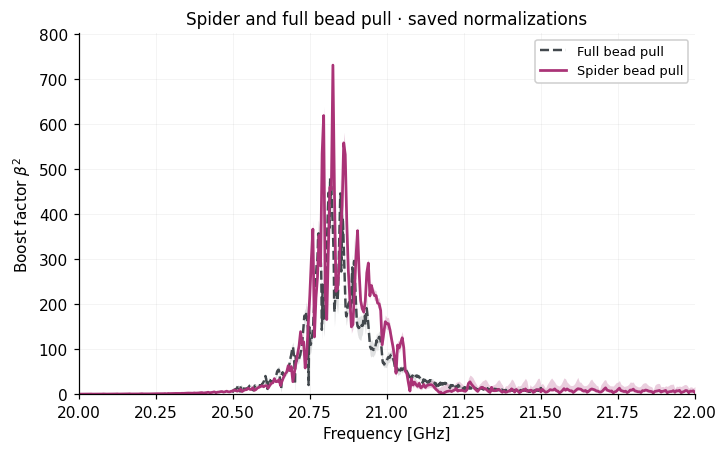

In [9]:
from src.full_bead_comparison import load_full_bead
full = load_full_bead("data/full_bead_pull/result_bf_21_0.jld2")
reference = {"frequency_hz": full.frequencies_Hz, "beta2_saved": full.beta2, "beta2_saved_error": full.beta2_error}
plots.present(
    plots.reference_figure(
        result, bands, reference, "Saved normalizations differ.",
        title='Spider and full bead pull · saved normalizations',
        x_label='Frequency [GHz]',
        y_label='Boost factor $\\beta^2$',
        full_curve_label='Full bead pull',
        spider_curve_label='Spider bead pull',
    ),
    FIGURE_DIR / "full_bead_comparison",
)

### Transverse field integrals

Top: finite-bead field and measured/line-derived estimates. Bottom: model field without the bead. Spider points use the same radial reconstruction as the 1D plots, placed at fitted thread midpoints. They are diagnostics, not 3D fit inputs; horizontal model sections differ from sloped measurement paths.

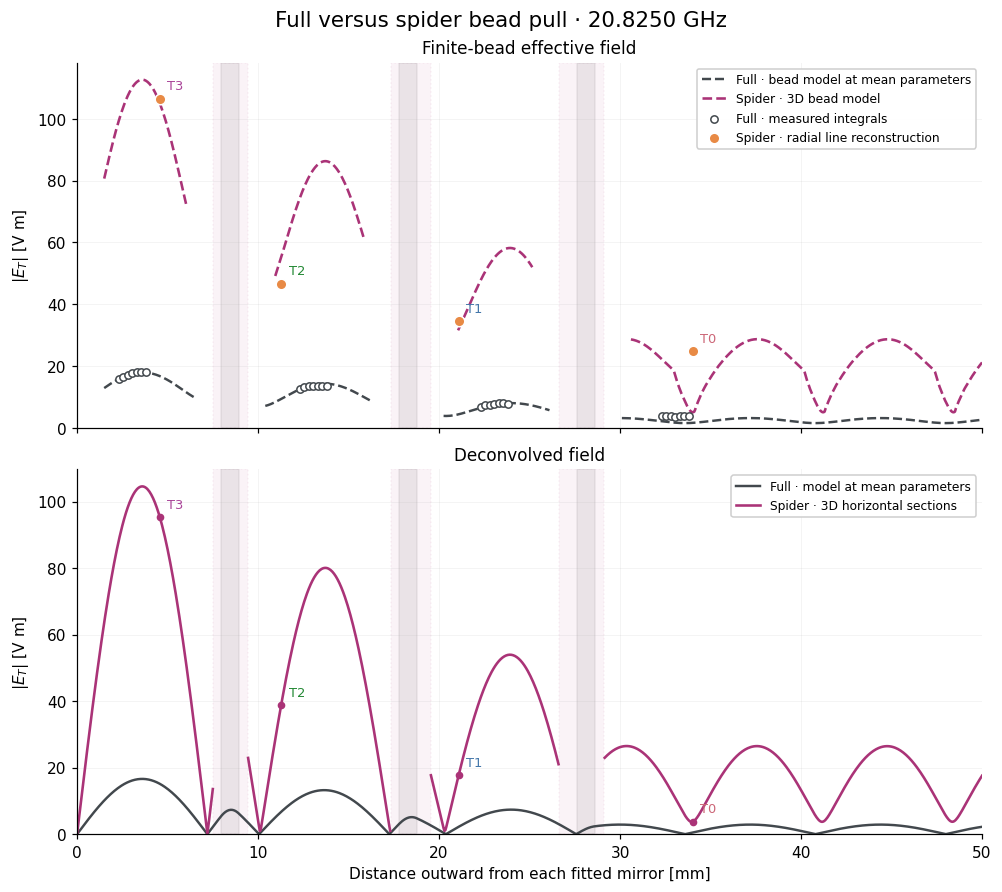

In [10]:
from src.analysis_3d_exports import longitudinal_field_integrals, measured_transverse_integrals
from src.full_bead_comparison import field_reference

sections = longitudinal_field_integrals(
    result, DATA / "bank", DATA / "beam_prior.npz", FREQUENCY_GHZ,
)
np.savez_compressed(DATA / "longitudinal_field_integrals.npz", **sections)
field_reference_data = field_reference(full, FREQUENCY_GHZ)
spider_field_estimates = measured_transverse_integrals(RUN_DIR, FREQUENCY_GHZ)
plots.present(
    plots.reference_field_figure(
        sections, field_reference_data,
        spider_estimates=spider_field_estimates,
        frequency_GHz=FREQUENCY_GHZ,
        title_template='Full versus spider bead pull · {frequency_GHz:.4f} GHz',
        x_label='Distance outward from each fitted mirror [mm]',
        y_label='$|E_T|$ [V m]',
        effective_field_title='Finite-bead effective field',
        deconvolved_field_title='Deconvolved field',
        full_bead_label='Full · bead model at mean parameters',
        spider_bead_label='Spider · 3D bead model',
        full_measured_label='Full · measured integrals',
        spider_measured_label='Spider · radial line reconstruction',
        full_curve_label='Full · model at mean parameters',
        spider_curve_label='Spider · 3D horizontal sections',
        thread_label_template='T{thread_index}',
    ),
    FIGURE_DIR / "full_bead_comparison",
)

## 9. Reprocess measurements (optional)

Set `REPROCESS=True` when ready. Frequencies outside 20–22 GHz are discarded before profile fitting; measured S22 is retained unchanged; beam samples are restricted before interpolation.

In [11]:
from src.analysis_3d_inputs import prepare_measurement, prepare_beam

REPROCESS = False
if REPROCESS:
    prepare_measurement(RUN_DIR, DATA / "measurement_inputs.npz")
    prepare_beam("data/reference_data/beam_measurements/beam_fit_S31.csv",
                 DATA / "beam_prior.npz", result["frequency_hz"])

## 10. Fit/evaluate (optional)

The local fitting bank has all 35 quality-selected frequencies. `data/3d/bank_full401` provides the dense 401-bin evaluation. The optional fitting cell below uses one start.

In [12]:
from src.analysis_3d import EndpointFitProblem, fit_full_tilt, save_result

EVALUATE_MODEL = False
RUN_FIT = False
if EVALUATE_MODEL or RUN_FIT:
    problem = EndpointFitProblem(DATA / "bank", DATA / "measurement_inputs.npz", DATA / "beam_prior.npz")
    parameters = np.asarray(geometry["parameters"])
    details = {"operation": "evaluation of saved geometry"}
    if RUN_FIT:
        # Start from measured central positions and measured relative disk slopes.
        initial = np.zeros(17)
        initial[3:9] = np.asarray(geometry["nominal_disk_slopes_mrad"]).ravel()
        optimization = fit_full_tilt(problem, initial, maxiter=180)
        parameters = optimization.x
        details = {"success": bool(optimization.success), "message": str(optimization.message),
                   "iterations": int(optimization.nit), "starts": 1, "geometry_refitted": True}
    record, evaluated = save_result(problem, parameters, "outputs/sbp_3d", details)

## 11. Export bands and maps (optional)

Requires the preceding evaluation. Bootstrap keeps geometry and illumination fixed.

In [13]:
from src.analysis_3d_exports import conditional_bands, midpoint_maps

EXPORT = False
if EXPORT:
    quantiles = conditional_bands(evaluated, problem.fit_threads, draws=1000)
    np.savez_compressed("outputs/sbp_3d/conditional_bands.npz", frequency_hz=evaluated["frequency_hz"],
                       quantiles=quantiles, quantile_probabilities=[.025, .16, .5, .84, .975])
    midpoint_maps(problem, parameters, "outputs/sbp_3d", frequencies_hz=[20.795e9,20.825e9])